In [31]:
import torch
import torch.nn as nn
import torch.nn.functional as F

In [32]:
# Create a Model class that inherits nn.Module
class Model(nn.Module):
    # Input layer contain 4 features
    # Hidden Layer1 (number of some neurons) -->
    # Hiddel Layer2 (number of some neurons) -->
    # output (3 classes of iris flowers)

    def __init__(self, input_features=4, hidden_layer1=8, hidden_layer2=9, output_features=3):
        super().__init__() # This instanciates nn.Module
        self.fully_connected_1 = nn.Linear(input_features, hidden_layer1)
        self.fully_connected_2 = nn.Linear(hidden_layer1, hidden_layer2)
        self.out = nn.Linear(hidden_layer2, output_features)


    def forward(self, x):
        x = F.relu(self.fully_connected_1(x))
        x = F.relu(self.fully_connected_2(x))
        x = self.out(x)
        return x

In [33]:
# Pick a manual seed for randomization
torch.manual_seed(41)

# Create an instance of Model
model = Model()

In [34]:
# Training with the data

In [35]:
import pandas as pd
import matplotlib.pyplot as plt

In [36]:
# Load the data
url = 'https://gist.githubusercontent.com/netj/8836201/raw/6f9306ad21398ea43cba4f7d537619d0e07d5ae3/iris.csv'
my_dataframe = pd.read_csv(url)

In [37]:
my_dataframe.tail()

,sepal.length,sepal.width,petal.length,petal.width,variety
145,6.7,3.0,5.2,2.3,Virginica
146,6.3,2.5,5.0,1.9,Virginica
147,6.5,3.0,5.2,2.0,Virginica
148,6.2,3.4,5.4,2.3,Virginica
149,5.9,3.0,5.1,1.8,Virginica


In [38]:
my_dataframe.head()

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,Setosa
1,4.9,3.0,1.4,0.2,Setosa
2,4.7,3.2,1.3,0.2,Setosa
3,4.6,3.1,1.5,0.2,Setosa
4,5.0,3.6,1.4,0.2,Setosa


In [39]:
# change last column from string to integer
my_dataframe['variety'] = my_dataframe['variety'].replace('Setosa', 0.0)
my_dataframe['variety'] = my_dataframe['variety'].replace('Versicolor', 1.0)
my_dataframe['variety'] = my_dataframe['variety'].replace('Virginica', 2.0)
my_dataframe

,sepal.length,sepal.width,petal.length,petal.width,variety
0,5.1,3.5,1.4,0.2,0.0
1,4.9,3.0,1.4,0.2,0.0
2,4.7,3.2,1.3,0.2,0.0
3,4.6,3.1,1.5,0.2,0.0
4,5.0,3.6,1.4,0.2,0.0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2.0
146,6.3,2.5,5.0,1.9,2.0
147,6.5,3.0,5.2,2.0,2.0
148,6.2,3.4,5.4,2.3,2.0


In [40]:
# Train and Test Split . Set X and y
X = my_dataframe.drop('variety', axis=1)
y = my_dataframe['variety']

In [41]:
# Convert these to numpy arrays
X = X.values
y = y.values

In [42]:
from sklearn.model_selection import train_test_split

In [43]:
# Train Test Split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=41)

In [44]:
# Convert X features to float tensors
X_train = torch.FloatTensor(X_train)
X_test = torch.FloatTensor(X_test)

In [45]:
# Convert y features to Long tesnors
import numpy as np
y_train = torch.LongTensor(y_train.astype(np.int64))
y_test = torch.LongTensor(y_test.astype(np.int64))

In [46]:
# Set the criterian of model to measure the error, how far off the predictions are from the data
criterian = nn.CrossEntropyLoss()

# Choose Adam Optmizer, lr = learning rate(if error does not go down after a bunch of iteration (epochs), lower our learning rate)
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

In [47]:
### Training our Model ###
# Epochs - one run through all the training data in our network
epochs = 100
losses = []

for i in range(epochs):
    # Go forward and get the prediction
    y_pred = model.forward(X_train) # Get the predicted results

    # Measure the loss/error , gonna be high at first
    loss = criterian(y_pred, y_train) # predicted values vs y_train

    # keep track of the losses
    losses.append(loss.detach().numpy())

    # print every 10 epoch to see the losses
    if i%10 ==0:
        print(f'Epoch: {i} and Loss: {loss}')

    # Do some back propagation: Take the error rate from the forward propagation and feed it back to the optimizer
    # thorugh the network to optimize the weights
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

Epoch: 0 and Loss: 1.125203251838684
Epoch: 10 and Loss: 1.0097211599349976
Epoch: 20 and Loss: 0.8162347078323364
Epoch: 30 and Loss: 0.585993230342865
Epoch: 40 and Loss: 0.4003389775753021
Epoch: 50 and Loss: 0.26794716715812683
Epoch: 60 and Loss: 0.1796349734067917
Epoch: 70 and Loss: 0.12165626138448715
Epoch: 80 and Loss: 0.08606515824794769
Epoch: 90 and Loss: 0.06522613018751144


Text(0.5, 0, 'Epoch')

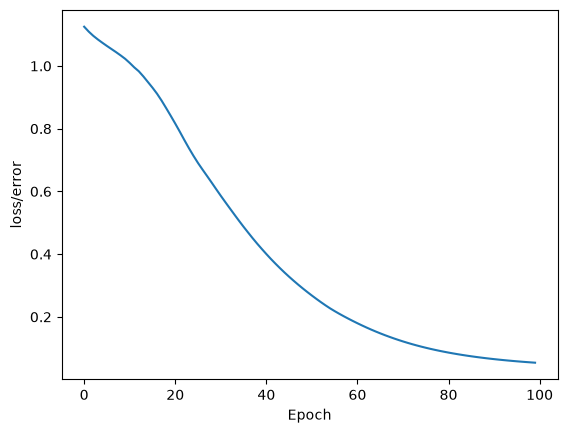

In [48]:
# graph out the epoch vs losses (could see the losses will reduce over multiple iteration of epochs)
plt.plot(range(epochs), losses)
plt.ylabel('loss/error')
plt.xlabel('Epoch')

In [49]:
# Evaluate Model on Test Data Set (validate model on test set)
with torch.no_grad(): # This disables back propagation
    y_eval = model.forward(X_test) # X_test are features from our test set and y_eval will be predictions
    loss = criterian(y_eval, y_test)

In [50]:
loss

tensor(0.1315)

In [52]:
correct_number_of_items = 0
with torch.no_grad():
    for i, data in enumerate(X_test):
        y_val = model(data)
        if y_test[i] == 0:
            x = "Setosa"
        elif y_test[i] == 1:
            x = 'Versicolor'
        else:
            x = 'Virginica'

        # This will tell what type of flower the network think it is 
        print(f'({i+1}.) {str(y_val)} \t {y_test[i]} \t {y_val.argmax().item()}')

        # add it to the correct variable
        if y_val.argmax().item() == y_test[i]:
            correct_number_of_items += 1
print(f'We got {correct_number_of_items} correct')


(1.) tensor([-5.8771,  4.4629,  6.5155]) 	 2 	 2
(2.) tensor([-7.5451,  4.1668,  9.7293]) 	 2 	 2
(3.) tensor([-8.4517,  5.1275, 10.2015]) 	 2 	 2
(4.) tensor([-4.3411,  5.6280,  2.5636]) 	 1 	 1
(5.) tensor([-7.1838,  4.8757,  8.3023]) 	 2 	 2
(6.) tensor([-3.3940,  5.3421,  1.2802]) 	 1 	 1
(7.) tensor([-5.9240,  4.9826,  6.0025]) 	 2 	 2
(8.) tensor([-4.2895,  5.7016,  2.3920]) 	 1 	 1
(9.) tensor([-6.5369,  4.9261,  7.1291]) 	 2 	 2
(10.) tensor([-8.0526,  4.4129, 10.3325]) 	 2 	 2
(11.) tensor([-5.6775,  4.9505,  5.6248]) 	 2 	 2
(12.) tensor([ 4.5748, -2.2579, -2.8925]) 	 0 	 0
(13.) tensor([ 4.2646, -2.0055, -2.7342]) 	 0 	 0
(14.) tensor([-2.1081,  4.0482,  0.5803]) 	 1 	 1
(15.) tensor([ 3.4608, -1.2147, -2.3488]) 	 0 	 0
(16.) tensor([-5.4739,  5.1174,  5.0966]) 	 2 	 1
(17.) tensor([ 4.0637, -1.8045, -2.6504]) 	 0 	 0
(18.) tensor([-5.8090,  4.6057,  6.2494]) 	 1 	 2
(19.) tensor([ 4.9250, -2.5763, -3.0545]) 	 0 	 0
(20.) tensor([ 3.4559, -1.2559, -2.3637]) 	 0 	 0
(21.) ten

In [54]:
# This is another version of code generated by AI for additional understanding

flower_names = ["Setosa", "Versicolor", "Virginica"]

correct = 0

model.eval()

with torch.no_grad():
    for i, data in enumerate(X_test):

        y_val = model(data)

        predicted = y_val.argmax().item()
        actual = y_test[i].item()

        print(
            f"{i+1}. Actual: {flower_names[actual]}, "
            f"Predicted: {flower_names[predicted]}"
        )

        if predicted == actual:
            correct += 1

print(f"Accuracy: {correct / len(X_test) * 100:.2f}%")

1. Actual: Virginica, Predicted: Virginica
2. Actual: Virginica, Predicted: Virginica
3. Actual: Virginica, Predicted: Virginica
4. Actual: Versicolor, Predicted: Versicolor
5. Actual: Virginica, Predicted: Virginica
6. Actual: Versicolor, Predicted: Versicolor
7. Actual: Virginica, Predicted: Virginica
8. Actual: Versicolor, Predicted: Versicolor
9. Actual: Virginica, Predicted: Virginica
10. Actual: Virginica, Predicted: Virginica
11. Actual: Virginica, Predicted: Virginica
12. Actual: Setosa, Predicted: Setosa
13. Actual: Setosa, Predicted: Setosa
14. Actual: Versicolor, Predicted: Versicolor
15. Actual: Setosa, Predicted: Setosa
16. Actual: Virginica, Predicted: Versicolor
17. Actual: Setosa, Predicted: Setosa
18. Actual: Versicolor, Predicted: Virginica
19. Actual: Setosa, Predicted: Setosa
20. Actual: Setosa, Predicted: Setosa
21. Actual: Versicolor, Predicted: Versicolor
22. Actual: Virginica, Predicted: Virginica
23. Actual: Setosa, Predicted: Setosa
24. Actual: Setosa, Predict

In [57]:
# testing with some manual values of an iris flower
new_iris = torch.tensor([4.5, 3.2, 1.3, 0.2])

with torch.no_grad():
    print(model(new_iris))

tensor([ 4.4735, -2.1916, -2.8328])


In [58]:
# testing with one more set of input data
another_iris = torch.tensor([5.9, 3.0, 5.1, 1.8])

with torch.no_grad():
    print(model(another_iris))

tensor([-5.9960,  4.5080,  6.6831])


In [59]:
### Save and Load the neural network model

In [60]:
# First save the model
torch.save(model.state_dict(), 'model_for_iris_classification.pt')

In [61]:
# Now load the model
new_model = Model()
new_model.load_state_dict(torch.load('model_for_iris_classification.pt'))

<All keys matched successfully>

In [62]:
# run eval() to make sure the model is loaded correctly
new_model.eval()

Model(
  (fully_connected_1): Linear(in_features=4, out_features=8, bias=True)
  (fully_connected_2): Linear(in_features=8, out_features=9, bias=True)
  (out): Linear(in_features=9, out_features=3, bias=True)
)